# 04 · Re-run with the feature set of `python_code/Statistical_Feature_Extraction.ipynb`

Notebooks 02–03 used features I designed. Here every experiment is repeated with **the feature set of the
project's own `Statistical_Feature_Extraction.ipynb`**, computed exactly as there (`sig2features` +
`eda_feature_extraction`, copied into `eda_utils.orig_descriptives` / `orig_phasic_features`):

* **12 descriptives** for each signal: mean, max, std, skew, norm1 (Σ|x|), median, min, range, mean slope
  (mean of first differences), kurtosis, sample entropy and approximate entropy (`nk.entropy_sample`,
  `nk.entropy_approximate`, defaults). Computed for the **raw EDA** (`eda_*`), the **tonic** (`tonic_*`) and the
  **phasic** (`phasic_*`) component.
* **12 phasic SCR/spectral features** (`nk.eda_peaks` on the phasic component): peak count, peak rate, mean / max /
  sum amplitude, mean and std rise time, mean recovery time, mean onset and offset time, rise/recovery ratio, and
  power of the phasic signal in 0.045–0.25 Hz.

→ **`raw` = 12 features**, and **`raw + decomposition` = 48 features** (12 + 12 tonic + 24 phasic), exactly the
48-column `feature_dataframe.csv` of the original notebook.

Only changes from the original code:
* `np.trapz`, removed in NumPy 2.x, falls back to `np.trapezoid`. Without it, the original silently returns NaN
  for `eda_symp_power`.
* The input is the raw 1-min window in µS, as in notebooks 02–03. The original used min-max-normalised,
  low-pass-filtered whole recordings with a 15 s stride and 80 % label purity.

SCR features are NaN when `eda_peaks` finds no peak, so every classifier gets a **median imputer fitted inside each
training fold**.

Setting: **no per-subject normalisation**, 1-min windows (10 s stride, 100 % purity), LOSO over 15 subjects.
**Every decomposition is applied to each 1-min window on its own.** Decompositions compared: NeuroKit2
`highpass` (default) and `smoothmedian`, sparsEDA, and `gmsEDA` over a 4 × 2 × 2 grid of
`num_of_chops` × `overlap` × `lam_scale`. As an extension that the original feature set does not have, the 12
descriptives are also computed on the **sparse driver** of `gmsEDA` and sparsEDA (`driver_*`, 60 features in total).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings, time, itertools
warnings.filterwarnings("ignore")
from eda_utils import *
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
import neurokit2 as nk
print("neurokit2", nk.__version__)

STRIDE = 10
W = np.load(CACHE / f"windows_stride{STRIDE}.npz")["W"]
meta = pd.read_csv(CACHE / f"windows_meta_stride{STRIDE}.csv")
y, groups = meta.label.values, meta.subject.values
FD = CACHE / "origfeat"; FD.mkdir(exist_ok=True)

neurokit2 0.2.13


## 1. Features for every decomposition (cached in `cache/origfeat/`)
Each feature table takes about 1 min to compute. Each `gmsEDA` configuration also needs its decomposition
(0.5–3 min).

In [2]:
t0 = time.time()
F = {"raw": original_feature_table(W, cache=FD / "raw.csv")}
for m in ["highpass", "smoothmedian"]:
    f = FD / f"nk_{m}.csv"
    if not f.exists():
        T, P = map(np.array, zip(*[nk.eda_phasic(w, sampling_rate=FS, method=m).values.T for w in W]))
    F[f"nk_{m}"] = original_feature_table(W, *( (None, None) if f.exists() else (T, P) ), cache=f)

if not (FD / "sparsEDA.csv").exists() or not (FD / "sparsEDA_drv.csv").exists():
    ST, SP_, SD = sparsEDA_windows(W)          # copy of nk's sparsEDA that also returns the driver (see notebook 03)
F["sparsEDA"] = original_feature_table(W, *((None, None) if (FD / "sparsEDA.csv").exists() else (ST, SP_)), cache=FD / "sparsEDA.csv")
F["sparsEDA_drv"] = original_feature_table(W, *((None, None, None) if (FD / "sparsEDA_drv.csv").exists() else (ST, SP_, SD)),
                                           cache=FD / "sparsEDA_drv.csv")

GRID = list(itertools.product([5, 10, 20, 40], [0.8, 0.9], [1, 3]))
for ch, ov, ls in GRID:
    tag = f"gms_c{ch}_o{ov:g}_l{ls:g}"
    if not ((FD / f"{tag}.csv").exists() and (FD / f"{tag}_drv.csv").exists()):
        Dr, T, P = gmsEDA_decompose_windows(W, dict(num_of_chops=ch, overlap=ov, lam_scale=ls, force_nn=0))
        original_feature_table(W, T, P, cache=FD / f"{tag}.csv")
        original_feature_table(W, T, P, Dr, cache=FD / f"{tag}_drv.csv")
    F[tag] = pd.read_csv(FD / f"{tag}.csv")
    F[f"{tag}_drv"] = pd.read_csv(FD / f"{tag}_drv.csv")
print(f"{time.time() - t0:.0f}s;", len(F), "feature tables;", "columns:", F["raw"].shape[1], "/", F["nk_highpass"].shape[1],
      "/", F["gms_c20_o0.9_l1_drv"].shape[1])
print("fraction of windows with no SCR peak found (phasic_peak_count == 0):")
print(pd.Series({k: (v.phasic_peak_count == 0).mean() for k, v in F.items() if "phasic_peak_count" in v}).round(3).to_string())

1s; 37 feature tables; columns: 12 / 48 / 60
fraction of windows with no SCR peak found (phasic_peak_count == 0):
nk_highpass            0.0
nk_smoothmedian        0.0
sparsEDA               0.0
sparsEDA_drv           0.0
gms_c5_o0.8_l1         0.0
gms_c5_o0.8_l1_drv     0.0
gms_c5_o0.8_l3         0.0
gms_c5_o0.8_l3_drv     0.0
gms_c5_o0.9_l1         0.0
gms_c5_o0.9_l1_drv     0.0
gms_c5_o0.9_l3         0.0
gms_c5_o0.9_l3_drv     0.0
gms_c10_o0.8_l1        0.0
gms_c10_o0.8_l1_drv    0.0
gms_c10_o0.8_l3        0.0
gms_c10_o0.8_l3_drv    0.0
gms_c10_o0.9_l1        0.0
gms_c10_o0.9_l1_drv    0.0
gms_c10_o0.9_l3        0.0
gms_c10_o0.9_l3_drv    0.0
gms_c20_o0.8_l1        0.0
gms_c20_o0.8_l1_drv    0.0
gms_c20_o0.8_l3        0.0
gms_c20_o0.8_l3_drv    0.0
gms_c20_o0.9_l1        0.0
gms_c20_o0.9_l1_drv    0.0
gms_c20_o0.9_l3        0.0
gms_c20_o0.9_l3_drv    0.0
gms_c40_o0.8_l1        0.0
gms_c40_o0.8_l1_drv    0.0
gms_c40_o0.8_l3        0.0
gms_c40_o0.8_l3_drv    0.0
gms_c40_o0.9_l1       

Sanity check: the cached raw-window descriptives agree with the original `sig2features` code (pandas row operations).

In [3]:
X = pd.DataFrame(W[:50])
ref = pd.DataFrame({"eda_mean": X.mean(axis=1), "eda_std": X.std(axis=1), "eda_skew": X.skew(axis=1),
                    "eda_kurtosis": X.kurtosis(axis=1), "eda_mean_slope": X.diff(axis=1).mean(axis=1)})
print("max |difference| vs pandas row-wise:", float(np.abs(ref.values - F["raw"][ref.columns].iloc[:50].values).max()))

max |difference| vs pandas row-wise: 1.1102230246251565e-15


## 2. `gmsEDA` parameter grid (screening with LogReg + HistGB)

In [4]:
MODELS = models_with_imputer()
SCREEN = {k: MODELS[k] for k in ["LogReg", "HistGB"]}
rows = []
t0 = time.time()
base = {}
for m, fn in SCREEN.items():
    base[m] = loso_eval(fn, F["raw"].values, y, groups)[0]["acc"]
for ch, ov, ls in GRID:
    tag = f"gms_c{ch}_o{ov:g}_l{ls:g}"
    for drv in ["", "_drv"]:
        for m, fn in SCREEN.items():
            s, _ = loso_eval(fn, F[tag + drv].values, y, groups)
            rows.append(dict(num_of_chops=ch, overlap=ov, lam_scale=ls, driver=bool(drv), model=m, acc=s["acc"]))
print(f"{time.time() - t0:.0f}s;  raw (12 features):", {k: round(v, 3) for k, v in base.items()})
scr = pd.DataFrame(rows)
S = scr.pivot_table(index=["num_of_chops", "overlap", "lam_scale"], columns=["driver", "model"], values="acc")
S[("mean", "no driver")] = S[False].mean(axis=1); S[("mean", "with driver")] = S[True].mean(axis=1)
S.sort_values(("mean", "no driver"), ascending=False).round(3)

234s;  raw (12 features): {'LogReg': 0.765, 'HistGB': 0.787}


driver                          False          True             mean            
model                          HistGB LogReg HistGB LogReg no driver with driver
num_of_chops overlap lam_scale                                                  
20           0.9     1          0.850  0.842  0.865  0.852     0.846       0.858
10           0.8     1          0.848  0.831  0.858  0.845     0.839       0.851
40           0.8     1          0.835  0.837  0.863  0.856     0.836       0.859
10           0.9     1          0.840  0.815  0.861  0.850     0.828       0.856
20           0.8     1          0.836  0.809  0.868  0.846     0.822       0.857
5            0.9     1          0.825  0.806  0.833  0.828     0.816       0.830
40           0.9     1          0.824  0.806  0.841  0.855     0.815       0.848
             0.8     3          0.831  0.788  0.825  0.784     0.810       0.804
20           0.9     3          0.818  0.787  0.821  0.783     0.802       0.802
             0.8     3          0.810  0.787  0.811  0.790     0.799       0.801
10           0.9     3          0.816  0.781  0.814  0.783     0.798       0.798
             0.8     3          0.813  0.783  0.817  0.785     0.798       0.801
5            0.8     3          0.814  0.777  0.822  0.778     0.795       0.800
                     1          0.802  0.782  0.801  0.781     0.792       0.791
             0.9     3          0.806  0.778  0.808  0.773     0.792       0.790
40           0.9     3          0.797  0.777  0.810  0.798     0.787       0.804

## 3. Main comparison (4 classifiers, paired per-subject tests vs `raw`)
The `gmsEDA` configurations shown are the old default (5 chops, 0.8, λ 3), the configuration chosen in notebook 02
(20 chops, 0.9, λ 1) and the best one of the screening above. Picking the best of the screen is optimistic;
section 4 gives the unbiased nested estimate.

In [5]:
best_tag = "gms_c%d_o%g_l%g" % S[("mean", "no driver")].idxmax()
best_tag_drv = "gms_c%d_o%g_l%g" % S[("mean", "with driver")].idxmax()
print("best in screen (no driver):", best_tag, "| (with driver):", best_tag_drv)
SETS = {"raw (12)": F["raw"],
        "raw + NeuroKit2 highpass": F["nk_highpass"],
        "raw + NeuroKit2 smoothmedian": F["nk_smoothmedian"],
        "raw + sparsEDA": F["sparsEDA"],
        "raw + gmsEDA c5 o0.8 λ3 (old default)": F["gms_c5_o0.8_l3"],
        "raw + gmsEDA c20 o0.9 λ1 (notebook 02)": F["gms_c20_o0.9_l1"],

        "raw + sparsEDA + driver": F["sparsEDA_drv"],
        "raw + gmsEDA c20 o0.9 λ1 + driver": F["gms_c20_o0.9_l1_drv"],
}
if best_tag != "gms_c20_o0.9_l1":
    SETS[f"raw + gmsEDA {best_tag[4:]} (best in screen)"] = F[best_tag]
if best_tag_drv != "gms_c20_o0.9_l1":
    SETS[f"raw + gmsEDA {best_tag_drv[4:]} + driver (best in screen)"] = F[best_tag_drv + "_drv"]
t0 = time.time()
res, ptab = compare_feature_sets(SETS, y, groups, models=MODELS, baseline="raw (12)")
print(f"{time.time() - t0:.0f}s")
acc = res.pivot(index="features", columns="model", values="acc").loc[list(SETS)]
acc["mean"] = acc.mean(axis=1)
acc.round(3)

best in screen (no driver): gms_c20_o0.9_l1 | (with driver): gms_c40_o0.8_l1
258s


model,HistGB,LogReg,RandomForest,SVM-RBF,mean
features,,,,,
raw (12),0.787,0.765,0.752,0.769,0.768
raw + NeuroKit2 highpass,0.874,0.834,0.860,0.883,0.863
raw + NeuroKit2 smoothmedian,0.856,0.826,0.864,0.858,0.851
raw + sparsEDA,0.831,0.832,0.851,0.856,0.843
raw + gmsEDA c5 o0.8 λ3 (old default),0.814,0.777,0.769,0.808,0.792
raw + gmsEDA c20 o0.9 λ1 (notebook 02),0.850,0.842,0.846,0.878,0.854
raw + sparsEDA + driver,0.829,0.832,0.855,0.857,0.843
raw + gmsEDA c20 o0.9 λ1 + driver,0.865,0.852,0.861,0.894,0.868
raw + gmsEDA c40_o0.8_l1 + driver (best in screen),0.863,0.856,0.854,0.894,0.867


In [6]:
f1 = res.pivot(index="features", columns="model", values="f1").loc[list(SETS)]
f1["mean"] = f1.mean(axis=1)
f1.round(3)

model,HistGB,LogReg,RandomForest,SVM-RBF,mean
features,,,,,
raw (12),0.768,0.719,0.734,0.728,0.737
raw + NeuroKit2 highpass,0.859,0.811,0.844,0.868,0.845
raw + NeuroKit2 smoothmedian,0.837,0.801,0.848,0.837,0.831
raw + sparsEDA,0.808,0.808,0.835,0.833,0.821
raw + gmsEDA c5 o0.8 λ3 (old default),0.797,0.736,0.753,0.779,0.766
raw + gmsEDA c20 o0.9 λ1 (notebook 02),0.834,0.821,0.831,0.860,0.837
raw + sparsEDA + driver,0.805,0.808,0.839,0.834,0.822
raw + gmsEDA c20 o0.9 λ1 + driver,0.851,0.832,0.846,0.880,0.852
raw + gmsEDA c40_o0.8_l1 + driver (best in screen),0.848,0.837,0.839,0.879,0.851


In [7]:
ptab.assign(cell=lambda d: d.apply(lambda r: f"{r.delta:+.3f} ({r.wins}/{r.losses}, p={r.p:.3f})", axis=1)) \
    .pivot(index="features", columns="model", values="cell").loc[list(SETS)[1:]]

model,HistGB,LogReg,RandomForest,SVM-RBF
features,,,,
raw + NeuroKit2 highpass,"+0.087 (13/0, p=0.001)","+0.070 (14/1, p=0.000)","+0.107 (11/2, p=0.003)","+0.114 (13/2, p=0.000)"
raw + NeuroKit2 smoothmedian,"+0.068 (12/2, p=0.002)","+0.062 (12/3, p=0.006)","+0.111 (12/1, p=0.002)","+0.088 (13/1, p=0.002)"
raw + sparsEDA,"+0.044 (10/4, p=0.030)","+0.068 (13/2, p=0.004)","+0.098 (13/1, p=0.002)","+0.086 (12/1, p=0.002)"
raw + gmsEDA c5 o0.8 λ3 (old default),"+0.026 (11/1, p=0.010)","+0.013 (11/4, p=0.151)","+0.017 (8/4, p=0.327)","+0.040 (9/6, p=0.334)"
raw + gmsEDA c20 o0.9 λ1 (notebook 02),"+0.062 (14/0, p=0.001)","+0.077 (10/5, p=0.008)","+0.094 (13/1, p=0.001)","+0.109 (14/1, p=0.000)"
raw + sparsEDA + driver,"+0.041 (10/4, p=0.026)","+0.068 (13/2, p=0.003)","+0.101 (12/2, p=0.003)","+0.087 (14/1, p=0.000)"
raw + gmsEDA c20 o0.9 λ1 + driver,"+0.078 (14/0, p=0.001)","+0.088 (13/2, p=0.003)","+0.108 (13/1, p=0.002)","+0.125 (14/1, p=0.001)"
raw + gmsEDA c40_o0.8_l1 + driver (best in screen),"+0.075 (14/0, p=0.001)","+0.092 (12/2, p=0.004)","+0.102 (13/1, p=0.003)","+0.125 (14/1, p=0.000)"


### Head-to-head: `gmsEDA` against the best non-`gmsEDA` decomposition
Rows without `+ driver` use the same 48 features as the reference. Rows with `+ driver` add the 12 driver
descriptives (60 features), which NeuroKit2 highpass cannot provide.

In [8]:
others = ["raw + NeuroKit2 highpass", "raw + NeuroKit2 smoothmedian", "raw + sparsEDA"]
best_other = max(others, key=lambda k: acc.loc[k, "mean"])
cands = [k for k in SETS if "gmsEDA" in k]
_, h2h = compare_feature_sets({best_other: SETS[best_other], **{k: SETS[k] for k in cands}},
                              y, groups, models=MODELS, baseline=best_other)
print("reference:", best_other)
h2h.pivot(index="features", columns="model", values="delta").round(3).join(
    h2h.pivot(index="features", columns="model", values="p").round(3), lsuffix=" Δ", rsuffix=" p")

reference: raw + NeuroKit2 highpass


model,HistGB Δ,LogReg Δ,RandomForest Δ,SVM-RBF Δ,HistGB p,LogReg p,RandomForest p,SVM-RBF p
features,,,,,,,,
raw + gmsEDA c20 o0.9 λ1 (notebook 02),-0.024,0.008,-0.013,-0.006,0.414,0.507,0.875,0.650
raw + gmsEDA c20 o0.9 λ1 + driver,-0.009,0.018,0.002,0.011,0.972,0.346,0.470,0.245
raw + gmsEDA c40_o0.8_l1 + driver (best in screen),-0.011,0.022,-0.005,0.011,0.944,0.272,0.975,0.132
raw + gmsEDA c5 o0.8 λ3 (old default),-0.060,-0.057,-0.090,-0.074,0.030,0.003,0.013,0.001


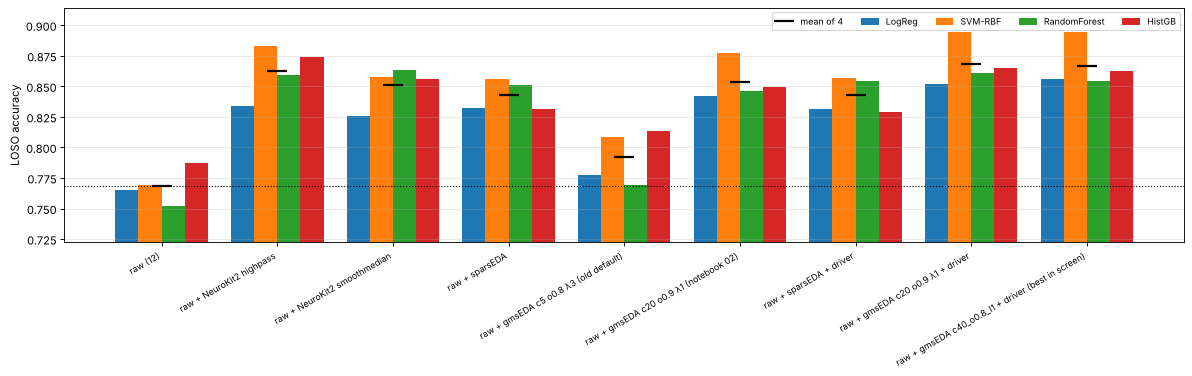

In [9]:
fig, ax = plt.subplots(figsize=(15, 4.8))
order = list(SETS); xs = np.arange(len(order))
for j, m in enumerate(["LogReg", "SVM-RBF", "RandomForest", "HistGB"]):
    ax.bar(xs + (j - 1.5) * 0.2, acc.loc[order, m].values, width=0.2, label=m)
ax.plot(xs, acc.loc[order, "mean"].values, "k_", ms=18, mew=2, label="mean of 4")
ax.axhline(acc.loc["raw (12)", "mean"], color="k", ls=":", lw=1)
ax.set_xticks(xs); ax.set_xticklabels(order, rotation=30, ha="right", fontsize=8)
lo = acc[["LogReg", "SVM-RBF", "RandomForest", "HistGB"]].values.min()
ax.set_ylim(lo - 0.03, acc.values.max() + 0.02); ax.set_ylabel("LOSO accuracy"); ax.legend(fontsize=8, ncol=5); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

## 4. Nested LOSO: is choosing a `gmsEDA` configuration still worth it?
For each held-out subject, the candidate is chosen by inner 5-fold group CV (LogReg) on the other 14 subjects from:
raw only, the three standard decompositions, and the 16 `gmsEDA` configurations (all without driver features, so all
use the original 48-feature set). It is then refit with LogReg and HistGB.

In [10]:
CANDS = {"raw": F["raw"], "nk_highpass": F["nk_highpass"], "nk_smoothmedian": F["nk_smoothmedian"], "sparsEDA": F["sparsEDA"]}
CANDS.update({f"gms_c{ch}_o{ov:g}_l{ls:g}": F[f"gms_c{ch}_o{ov:g}_l{ls:g}"] for ch, ov, ls in GRID})
t0 = time.time()
nest, chosen = nested_select_loso(CANDS, y, groups, MODELS["LogReg"], {k: MODELS[k] for k in ["LogReg", "HistGB"]})
print(f"{time.time() - t0:.0f}s")
print(chosen.chosen.value_counts().to_string())
nest.round(3)

45s
chosen
gms_c20_o0.9_l1    11
nk_highpass         4


,acc,f1
LogReg,0.830,0.809
HistGB,0.851,0.836


## Conclusion

**With the original feature set, `gmsEDA` is no better than NeuroKit2's default decomposition.** Mean LOSO
accuracy over 4 classifiers (1-min windows, no per-subject normalisation):

| features | # | mean acc | Δ vs raw |
|---|---|---|---|
| raw (eda_* descriptives) | 12 | 0.768 | – |
| raw + gmsEDA, old default (5 chops, 0.8, λ 3) | 48 | 0.792 | +0.024 |
| raw + sparsEDA | 48 | 0.843 | +0.075 |
| raw + NeuroKit2 smoothmedian | 48 | 0.851 | +0.083 |
| raw + gmsEDA (20 chops, 0.9, λ 1) | 48 | 0.854 | +0.086 |
| **raw + NeuroKit2 highpass (default)** | 48 | **0.863** | **+0.095** |
| raw + gmsEDA (20, 0.9, λ 1) + driver descriptives | 60 | 0.868 | +0.100 |

* **Every decomposition helps a lot** compared with the 12 raw descriptives: +7.5 to +9.5 points, 10–14 of 15 subjects,
  p ≤ 0.03. The exception is `gmsEDA` with its old defaults, which gains only +2.4 points. With this feature set the
  phasic SCR features from `nk.eda_peaks` carry much of the information, whichever method produced the phasic part.
* **`gmsEDA` vs NeuroKit2 highpass:** with the same 48 features, the tuned `gmsEDA` is slightly *behind*
  (−2.4 to +0.8 points, no difference significant, p ≥ 0.41). Adding the 12 driver descriptives brings `gmsEDA` to 0.868,
  slightly ahead (−1.1 to +2.2 points), but not significantly (p ≥ 0.13). The old defaults are significantly worse than
  NeuroKit2 (−6 to −9 points, p ≤ 0.03).
* **Parameters:** the same region as in notebook 02 is best. 20 chops, overlap 0.9, λ-scale 1 tops the screen,
  and λ-scale 3 is clearly worse for every chop/overlap setting.
* **Nested LOSO:** choosing among raw, NeuroKit2, sparsEDA and 16 `gmsEDA` configurations inside each fold picks
  `gmsEDA` (20, 0.9, λ 1) in 11 of 15 folds and NeuroKit2 highpass in 4. It reaches 0.830 (LogReg) / 0.851 (HistGB).
  That is no better than simply using NeuroKit2 highpass (0.834 / 0.874).

**Taken together with notebooks 02–03:** whether `gmsEDA` beats the standard decompositions depends on the features.
With the features of notebooks 02–03 (which include event counts of the sparse driver) `gmsEDA` was clearly best
(0.875 vs 0.847). With the project's original feature set (descriptives + `eda_peaks` SCR features on the phasic part)
NeuroKit2's simple high-pass split is as good. The tuned `gmsEDA` is only competitive when its driver is also
described (0.868), and not significantly better. The highest no-normalisation accuracy is about the same for both
feature sets (0.875 vs 0.868).